# Step 5. EDA & Visualization — Seasonal Analysis

## Objective

This notebook explores how arrival delays differ across the four seasons for flights departing from New York City airports in 2013.

We compare seasonal delay statistics, delay rates, and distributions to identify patterns that may be useful for airline operations planning.

This is an exploratory analysis. Statistical significance and the effects of other variables will be examined in the next milestone.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load cleaned flight data from Step 3
data_path = Path("data/cleaned/analysis_ready_flights.csv")
analysis = pd.read_csv(data_path)

season_order = ["Winter", "Spring", "Summer", "Fall"]

print("Dataset shape:", analysis.shape)
print("Missing arrival delays:", analysis["arr_delay"].isna().sum())
print("Missing seasons:", analysis["season"].isna().sum())

display(analysis[["season", "arr_delay"]].head())

Dataset shape: (327346, 34)
Missing arrival delays: 0
Missing seasons: 0


,season,arr_delay
0,Winter,11.0
1,Winter,20.0
2,Winter,33.0
3,Winter,-18.0
4,Winter,-25.0


## 1. Data Validation

Before analyzing seasonal patterns, we check that all four seasons are represented and that arrival delay values are available.

In [2]:
# Check season categories and sample sizes
season_counts = (
    analysis["season"]
    .value_counts()
    .reindex(season_order)
)

display(season_counts.to_frame("Flights"))

assert analysis["arr_delay"].notna().all(), "Missing arrival delays found."
assert analysis["season"].isin(season_order).all(), "Unexpected season values found."
assert season_counts.notna().all(), "One or more seasons are missing."

print("Seasonal data validation passed!")

,Flights
season,
Winter,77029
Spring,83594
Summer,84124
Fall,82599


Seasonal data validation passed!


## 2. Seasonal Descriptive Statistics

We calculate the number of flights, mean and median arrival delays, standard deviation, and delay rates for each season.

A flight is considered delayed by more than 15 minutes when its arrival delay is greater than 15 minutes.

In [3]:
seasonal_stats = (
    analysis.groupby("season")["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100
    )
    .reindex(season_order)
)

display(seasonal_stats.round(2))

,Flights,Mean,Median,Std,Min,Max,Delay_Over_15_Pct,Delay_Over_60_Pct
season,,,,,,,,
Winter,77029,9.04,-2.0,42.47,-70.0,1272.0,26.26,8.29
Spring,83594,6.81,-5.0,45.41,-86.0,931.0,24.23,8.82
Summer,84124,12.99,-3.0,52.50,-68.0,1127.0,28.64,12.29
Fall,82599,-1.22,-9.0,34.79,-68.0,1007.0,15.80,4.47


In [4]:
# Compare shared seasonal statistics with Step 4
step4_seasonal = pd.read_csv(
    "results/tables/seasonal_stats.csv",
    index_col=0
)

shared_columns = [
    "Flights", "Mean", "Median", "Std", "Min", "Max"
]

pd.testing.assert_frame_equal(
    seasonal_stats[shared_columns].round(2),
    step4_seasonal[shared_columns].round(2),
    check_dtype=False
)

print("Step 4 and Step 5 seasonal statistics match!")

Step 4 and Step 5 seasonal statistics match!


## 3. Mean vs. Median Arrival Delay by Season

Compare mean and median arrival delays across the four seasons to examine differences in typical delays and the possible influence of extreme values.

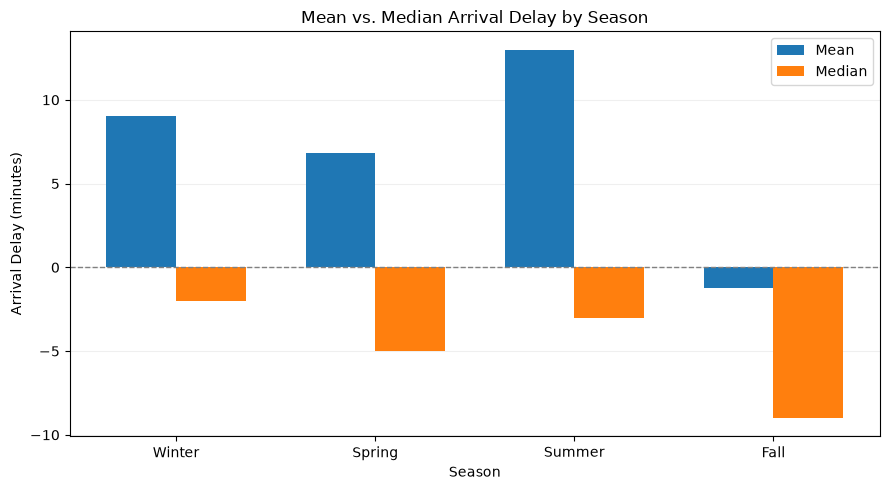

In [5]:
fig_dir = Path("results/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(season_order))
width = 0.35

ax.bar(
    x - width / 2,
    seasonal_stats["Mean"],
    width,
    label="Mean"
)

ax.bar(
    x + width / 2,
    seasonal_stats["Median"],
    width,
    label="Median"
)

ax.set_xticks(x)
ax.set_xticklabels(season_order)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)

ax.set(
    title="Mean vs. Median Arrival Delay by Season",
    xlabel="Season",
    ylabel="Arrival Delay (minutes)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    fig_dir / "seasonal_mean_vs_median.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 4. Delay Rates by Season

Compare the percentage of flights arriving more than 15 minutes and more than 60 minutes late across seasons.

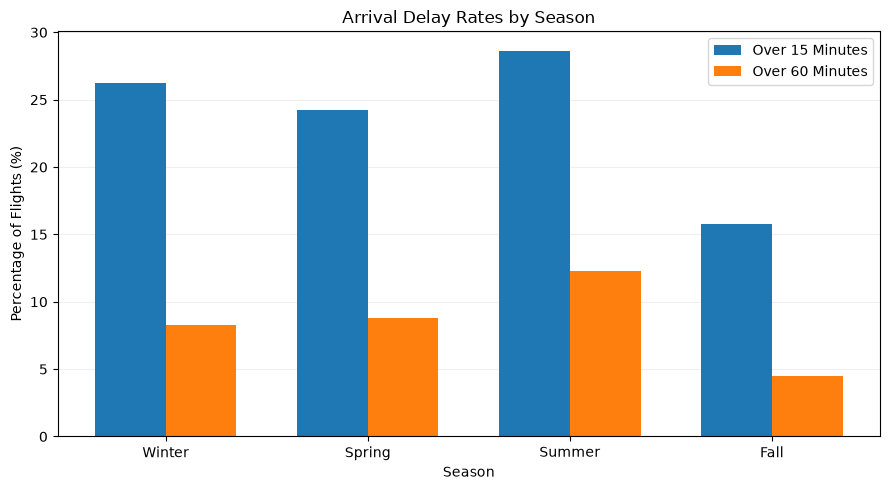

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    seasonal_stats["Delay_Over_15_Pct"],
    width,
    label="Over 15 Minutes"
)

ax.bar(
    x + width / 2,
    seasonal_stats["Delay_Over_60_Pct"],
    width,
    label="Over 60 Minutes"
)

ax.set_xticks(x)
ax.set_xticklabels(season_order)

ax.set(
    title="Arrival Delay Rates by Season",
    xlabel="Season",
    ylabel="Percentage of Flights (%)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    fig_dir / "seasonal_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 5. Arrival Delay Distribution by Season

Examine how arrival delay distributions differ across seasons. The plot focuses on delays between −60 and 180 minutes for readability, while the descriptive statistics include all observations.

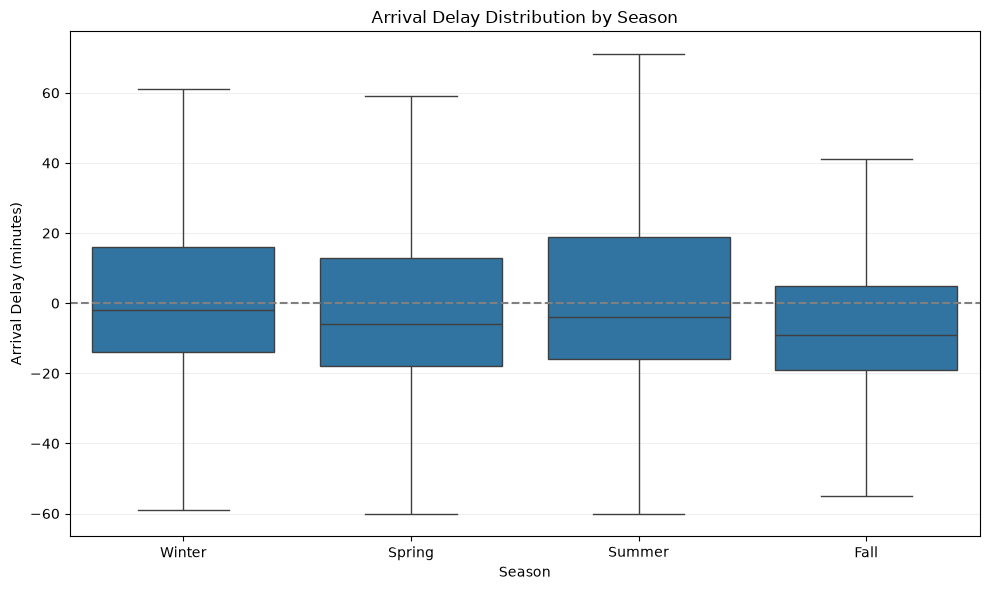

In [7]:
plot_data = analysis[
    analysis["arr_delay"].between(-60, 180)
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=plot_data,
    x="season",
    y="arr_delay",
    order=season_order,
    showfliers=False,
    ax=ax
)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Arrival Delay Distribution by Season",
    xlabel="Season",
    ylabel="Arrival Delay (minutes)"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    fig_dir / "seasonal_delay_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 6. Extreme Delays & Sample Sizes

Examine the number and percentage of flights with extreme arrival delays (over 120 minutes) and compare sample sizes across seasons.

This helps us understand whether extreme delays may influence seasonal averages.

In [8]:
# Calculate extreme delay statistics by season
extreme_stats = (
    analysis.groupby("season")["arr_delay"]
    .agg(
        Flights="count",
        Delays_Over_120=lambda x: (x > 120).sum(),
        Extreme_Delay_Pct=lambda x: (x > 120).mean() * 100,
        Maximum_Delay="max"
    )
    .reindex(season_order)
)

display(extreme_stats.round(2))

,Flights,Delays_Over_120,Extreme_Delay_Pct,Maximum_Delay
season,,,,
Winter,77029,2101,2.73,1272.0
Spring,83594,2603,3.11,931.0
Summer,84124,4090,4.86,1127.0
Fall,82599,1240,1.50,1007.0


### Extreme Delay Rates by Season

Compare the percentage of flights arriving more than 120 minutes late across the four seasons.

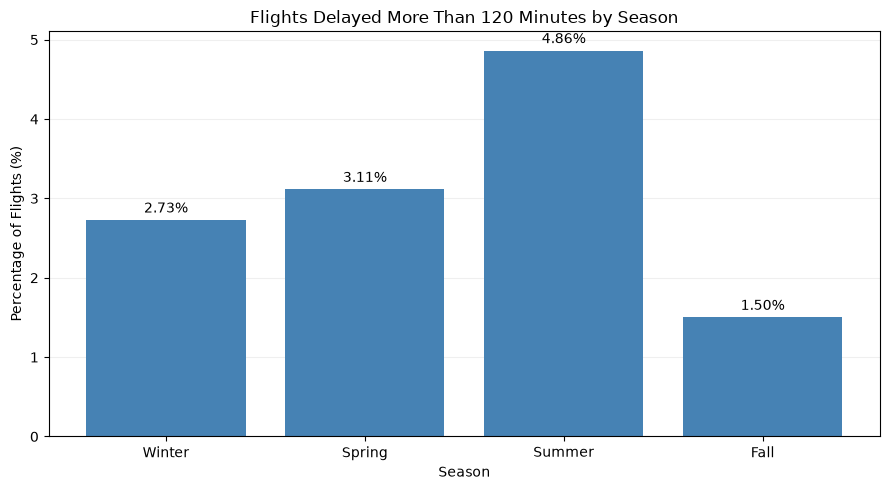

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    extreme_stats.index,
    extreme_stats["Extreme_Delay_Pct"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set(
    title="Flights Delayed More Than 120 Minutes by Season",
    xlabel="Season",
    ylabel="Percentage of Flights (%)"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "seasonal_extreme_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Compare sample sizes across seasons
sample_sizes = seasonal_stats[["Flights"]].copy()

sample_sizes["Share_of_Total_Pct"] = (
    sample_sizes["Flights"] / len(analysis) * 100
)

display(sample_sizes.round(2))

print(
    "Total flights:",
    f"{sample_sizes['Flights'].sum():,}"
)

,Flights,Share_of_Total_Pct
season,,
Winter,77029,23.53
Spring,83594,25.54
Summer,84124,25.70
Fall,82599,25.23


Total flights: 327,346


In [11]:
# Save seasonal statistics
table_dir = Path("results/tables")
table_dir.mkdir(parents=True, exist_ok=True)

seasonal_stats.round(2).to_csv(
    table_dir / "seasonal_statistics.csv",
    index_label="season"
)

extreme_stats.round(2).to_csv(
    table_dir / "seasonal_extreme_delays.csv",
    index_label="season"
)

print("Saved: results/tables/seasonal_statistics.csv")
print("Saved: results/tables/seasonal_extreme_delays.csv")

Saved: results/tables/seasonal_statistics.csv
Saved: results/tables/seasonal_extreme_delays.csv


## 8. Key Findings & Limitations

Summarize the main seasonal patterns and discuss the limitations of this exploratory analysis.

In [12]:
# Identify seasons with the highest and lowest delays
highest_mean = seasonal_stats["Mean"].idxmax()
lowest_mean = seasonal_stats["Mean"].idxmin()

highest_15 = seasonal_stats["Delay_Over_15_Pct"].idxmax()
lowest_15 = seasonal_stats["Delay_Over_15_Pct"].idxmin()

highest_60 = seasonal_stats["Delay_Over_60_Pct"].idxmax()
highest_120 = extreme_stats["Extreme_Delay_Pct"].idxmax()

print(
    f"Highest mean delay: {highest_mean} "
    f"({seasonal_stats.loc[highest_mean, 'Mean']:.2f} minutes)"
)

print(
    f"Lowest mean delay: {lowest_mean} "
    f"({seasonal_stats.loc[lowest_mean, 'Mean']:.2f} minutes)"
)

print(
    f"Highest >15 min delay rate: {highest_15} "
    f"({seasonal_stats.loc[highest_15, 'Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Lowest >15 min delay rate: {lowest_15} "
    f"({seasonal_stats.loc[lowest_15, 'Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Highest >60 min delay rate: {highest_60} "
    f"({seasonal_stats.loc[highest_60, 'Delay_Over_60_Pct']:.2f}%)"
)

print(
    f"Highest >120 min delay rate: {highest_120} "
    f"({extreme_stats.loc[highest_120, 'Extreme_Delay_Pct']:.2f}%)"
)

Highest mean delay: Summer (12.99 minutes)
Lowest mean delay: Fall (-1.22 minutes)
Highest >15 min delay rate: Summer (28.64%)
Lowest >15 min delay rate: Fall (15.80%)
Highest >60 min delay rate: Summer (12.29%)
Highest >120 min delay rate: Summer (4.86%)


### Key Findings

Summer had the highest mean arrival delay (12.99 minutes), while Fall had the lowest (−1.22 minutes). Summer also had the highest percentage of flights delayed more than 15 minutes (28.64%), 60 minutes (12.29%), and 120 minutes (4.86%).

Fall showed the lowest delay rates for flights delayed more than 15 minutes (15.80%) and 60 minutes (4.47%).

The mean arrival delay was higher than the median in every season, suggesting that some large delays may have increased the seasonal averages. Summer also had the highest standard deviation (52.50 minutes), indicating greater variation in arrival delays.

Overall, Summer showed the greatest arrival delay problems among the four seasons based on the measures examined.

### Limitations

This analysis only includes flights departing from New York City airports in 2013, so the findings may not represent current flight operations.

Seasonal differences may also be related to airline, scheduled departure time, flight distance, and weather conditions. These factors are not controlled for in this analysis.

Extreme delays may influence the mean arrival delay. In addition, these results are descriptive and do not establish that season itself causes flight delays. Further statistical analysis is needed to examine these relationships.